<a href="https://colab.research.google.com/github/hugo12341234/machine-learning-projects/blob/main/03-fashion-mnist-pytorch/fashion_mnist_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 3: Fashion Image Classifier with PyTorch

**Author:** Hugo Chacón · **Course:** SIAFI

## Project workflow

I follow the workflow from the book *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* by Aurélien Géron:

1. Look at the big picture.
2. Get the data.
3. Discover and visualize the data to gain insights.
4. Prepare the data for machine learning algorithms.
5. Select a model and train it.
6. Fine-tune the model.
7. Present the solution.

## Step 1. Look at the big picture

**Problem type:** supervised multiclass classification.

We have images with their correct labels, and the goal is to assign each image to one of 10 categories.

The data is not stored as image files (.jpg, .png). Instead, each image is flattened into one row of a comma-separated (CSV) file.

## Step 2. Get the data

File: `fashion-mnist_test.csv`

- **Rows:** 10,000
- **Columns:** 785 (1 `label` column + 784 pixel columns, `pixel1` to `pixel784`)
- **Training set:** 8,000 samples (80%)
- **Test set:** 2,000 samples (20%) for the final evaluation

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# Select the device (GPU if available, otherwise CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# 1. Load the raw CSV
df = pd.read_csv('fashion-mnist_test.csv')

# 2. Split features (pixels) and labels
# The first column is the label; the rest are the pixels
X = df.iloc[:, 1:].values  # Pixels (0-255)
y = df.iloc[:, 0].values   # Labels (0-9)

# 3. Train/test split (80% / 20%), stratified so every class keeps its proportion
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

# Label names, to know what each number means
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

FileNotFoundError: [Errno 2] No such file or directory: 'fashion-mnist_test.csv'

## Step 3. Discover and visualize the data

- **Data format:** the images are 28×28 pixels in grayscale.
- After loading with `pd.read_csv`, pixel values range from 0 to 255.
- Labels are numbers (0–9), so I created a list that maps them to readable names (T-shirt, Trouser, etc.).
- Items such as **Trouser** and **Bag** have very distinctive shapes.
- However, **Shirt**, **T-shirt**, **Coat** and **Pullover** look very similar. I expect the network to struggle most with these classes.

Training set examples:


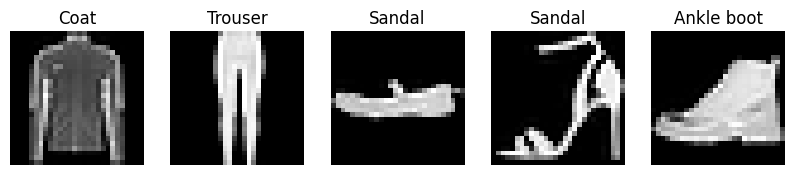

In [ ]:
def visualize_samples(X, y, classes, samples_per_class=5):
    plt.figure(figsize=(10, 5))
    for index in range(samples_per_class):
        plt.subplot(1, samples_per_class, index + 1)

        # Reshape the 784-value row into a 28x28 image
        image = X[index].reshape(28, 28)

        plt.imshow(image, cmap='gray')
        plt.title(classes[y[index]])
        plt.axis('off')
    plt.show()

print("Training set examples:")
visualize_samples(X_train, y_train, class_names)

## Step 4. Prepare the data

This was the most technical part of the project. Here is why each component is used:

- **`FashionDataset` class:** a custom PyTorch `Dataset` that takes a row from the CSV, converts it into a tensor and hands it to the model.
- **Normalization:** the original pixels range from 0 (black) to 255 (white). Large input values destabilize the gradients during training, so I scale the pixels to the [0, 1] range. This makes training faster and more stable.
- **DataLoaders:** instead of feeding all 8,000 images at once (which could exhaust the RAM), the `DataLoader` splits the data into mini-batches of 64 images, so the network learns batch by batch.

In [ ]:
class FashionDataset(Dataset):
    def __init__(self, features, labels):
        # Convert to tensors
        self.features = torch.tensor(features, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

        # Normalization
        # Scale the pixels from [0, 255] to [0, 1]
        self.features = self.features / 255.0
        # (Optional) Center them in [-1, 1]: self.features = (self.features - 0.5) / 0.5

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # When the DataLoader asks for an item, return (image, label)
        return self.features[idx], self.labels[idx]

# Create the Dataset objects
train_dataset = FashionDataset(X_train, y_train)
test_dataset = FashionDataset(X_test, y_test)

# Create the DataLoaders (mini-batches)
BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

## Step 5. Select a model and train it (network architecture)

I built a **multilayer perceptron (MLP)**. These are its components:

- **Flattening (784 inputs):** each 28×28 image arrives as a single row of 784 numbers. The model no longer knows which pixel is above or below another, so it only sees a list of values. This limits the maximum accuracy an MLP can reach compared with a convolutional network.
- **Hidden layers (256 and 128 neurons):** a "funnel" structure (784 → 256 → 128 → 10) forces the network to compress the information and keep only the most important features, such as shapes and edges, while discarding noise.
- **`nn.ReLU`:** without it, the network would be one big linear transformation, like a simple regression. ReLU lets it learn complex, non-linear relationships.
- **`nn.BatchNorm1d`:** works like a quality check between layers. It re-centers the activations before passing them to the next layer, which speeds up learning considerably.
- **`nn.Dropout(0.3)`:** during training, 30% of the neurons are randomly switched off. This keeps the network from relying on a single neuron to recognize, say, a boot, and makes it more robust against overfitting.
- **Adam optimizer:** more efficient than classic stochastic gradient descent (SGD) because it adapts the learning rate automatically.

In [ ]:
class FashionMLP(nn.Module):
    def __init__(self):
        super(FashionMLP, self).__init__()
        self.model = nn.Sequential(
            # Input layer (784 neurons) -> Hidden layer 1 (256)
            nn.Linear(784, 256),
            nn.BatchNorm1d(256), # Normalizes activations to speed up training
            nn.ReLU(),           # Non-linear activation
            nn.Dropout(0.3),     # Randomly drops 30% of neurons (regularization)

            # Hidden layer 1 (256) -> Hidden layer 2 (128)
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            # Hidden layer 2 (128) -> Output (10 classes)
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.model(x)

# Initialize the model, loss function and optimizer
model = FashionMLP().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

### Training results

The network reaches about **85% accuracy on the test set** (peaking at 85.7% around epoch 15), while it fits the training data noticeably better.

In other words, the model behaves like a student who memorizes: it does very well on the practice exercises (training set) but scores lower on the final exam (test set).

The reason is that a fairly powerful network was trained on very little data (only 8,000 images), so it started memorizing details specific to those images that do not generalize.

In [ ]:
def train_model(model, train_loader, test_loader, epochs=15):
    train_losses = []
    test_accuracies = []

    for epoch in range(epochs):
        # --- TRAINING PHASE ---
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()           # 1. Clear old gradients
            outputs = model(images)         # 2. Prediction (forward pass)
            loss = criterion(outputs, labels) # 3. Compute the loss
            loss.backward()                 # 4. Compute gradients (backward pass)
            optimizer.step()                # 5. Update the weights

            running_loss += loss.item()

        # --- EVALUATION PHASE ---
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad(): # No gradients needed here, which saves memory
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        epoch_acc = 100 * correct / total
        avg_loss = running_loss / len(train_loader)

        train_losses.append(avg_loss)
        test_accuracies.append(epoch_acc)

        if (epoch+1) % 5 == 0:
            print(f"Epoch [{epoch+1}/{epochs}] | Loss: {avg_loss:.4f} | Test Accuracy: {epoch_acc:.2f}%")

    return train_losses, test_accuracies

losses, accuracies = train_model(model, train_loader, test_loader, epochs=20)

Epoch [5/20] | Loss: 0.3919 | Test Accuracy: 81.65%
Epoch [10/20] | Loss: 0.3039 | Test Accuracy: 84.75%
Epoch [15/20] | Loss: 0.2506 | Test Accuracy: 85.70%
Epoch [20/20] | Loss: 0.1910 | Test Accuracy: 84.80%


## Step 7. Present the solution

I built a complete pipeline that ingests raw CSV data and produces predictions. An accuracy of about 85% shows that the chosen architecture can learn visual patterns.

The confusion matrix confirms that the model struggles to tell similar upper-body garments apart (Shirt vs. T-shirt), while it is very accurate on footwear and trousers.

**Next steps:**

- The easiest way to go from 85% to about 90% is to train on the full dataset (60,000 images).
- A convolutional neural network (CNN) would keep the spatial structure of the images and should improve accuracy further.

In [ ]:
# Get all predictions for the test set
y_pred = []
y_true = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        y_pred.extend(predicted.cpu().numpy())
        y_true.extend(labels.cpu().numpy())

# Confusion matrix plot
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Fashion-MNIST')
plt.show()

# Detailed classification report
print(classification_report(y_true, y_pred, target_names=class_names))

NameError: name 'model' is not defined